In [58]:
import pandas as pd

In [59]:
campaigns = pd.read_csv("../data/northbound_campaigns.csv")

In [60]:
campaigns.head()

,campaign_id,week_start,channel,discount_offer,spend,impressions,clicks,conversions,revenue
0,NB0001,2023-01-02,Social,0,2496.05,355888,3164,65,6125.44
1,NB0002,2023-01-09,Search,0,4512.46,198756,9592,220,20834.90
2,NB0003,2023-01-09,Social,0,2722.19,390272,3793,52,4803.85
3,NB0004,2023-01-09,Display,0,3414.22,1259415,6536,60,5424.96
4,NB0005,2023-01-09,Video,1,4393.00,314891,2885,52,4318.38


In [61]:
print('Rows and columns:', campaigns.shape)
print('First week:', campaigns['week_start'].min(),
      'Last week:', campaigns['week_start'].max())
print('Missing values in the whole table:', campaigns.isna().sum().sum())

Rows and columns: (441, 9)
First week: 2023-01-02 Last week: 2025-12-29
Missing values in the whole table: 0


In [62]:
campaigns.describe()

,discount_offer,spend,impressions,clicks,conversions,revenue
count,441.000000,441.000000,4.410000e+02,441.000000,441.000000,441.000000
mean,0.287982,4515.389524,5.097811e+05,5912.539683,162.680272,14825.101134
std,0.453337,2430.783140,4.213068e+05,3767.812582,165.469346,15085.349343
min,0.000000,605.720000,4.201200e+04,936.000000,5.000000,526.370000
25%,0.000000,2730.400000,2.264550e+05,3384.000000,52.000000,4696.480000
50%,0.000000,3991.990000,3.702860e+05,4780.000000,93.000000,8691.830000
75%,1.000000,5841.170000,6.422740e+05,7328.000000,208.000000,19089.650000
max,1.000000,15587.120000,2.575538e+06,29022.000000,940.000000,90259.370000


In [63]:
campaigns.info()

<class 'pandas.DataFrame'>
RangeIndex: 441 entries, 0 to 440
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   campaign_id     441 non-null    str    
 1   week_start      441 non-null    str    
 2   channel         441 non-null    str    
 3   discount_offer  441 non-null    int64  
 4   spend           441 non-null    float64
 5   impressions     441 non-null    int64  
 6   clicks          441 non-null    int64  
 7   conversions     441 non-null    int64  
 8   revenue         441 non-null    float64
dtypes: float64(2), int64(4), str(3)
memory usage: 31.1 KB


In [64]:
campaigns['impressions_k'] = campaigns['impressions'] / 1000
campaigns[['campaign_id', 'channel', 'impressions', 'impressions_k', 'conversions']].head()

,campaign_id,channel,impressions,impressions_k,conversions
0,NB0001,Social,355888,355.888,65
1,NB0002,Search,198756,198.756,220
2,NB0003,Social,390272,390.272,52
3,NB0004,Display,1259415,1259.415,60
4,NB0005,Video,314891,314.891,52


In [65]:
campaigns['channel'].unique()

<StringArray>
['Social', 'Search', 'Display', 'Video']
Length: 4, dtype: str

In [66]:
print(campaigns['channel'].value_counts())

channel
Search     151
Social     127
Display     90
Video       73
Name: count, dtype: int64


<Axes: xlabel='impressions_k', ylabel='conversions'>

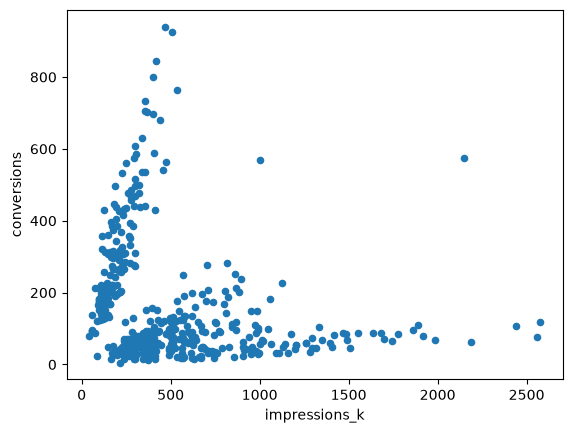

In [67]:
campaigns[['impressions_k', 'conversions']].plot.scatter(x='impressions_k',
                                                        y='conversions')

In [68]:
import matplotlib.pyplot as plt

In [69]:
channel_colours = {'Search': 'tab:blue',
                   'Social': 'tab:orange',
                   'Display': 'tab:green',
                   'Video': 'tab:purple'}

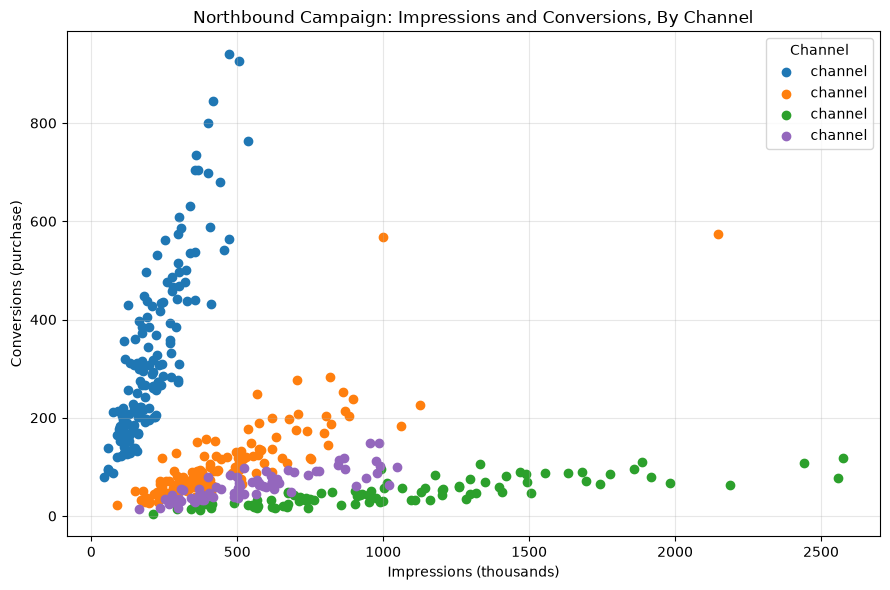

In [71]:
plt.figure(figsize=(9, 6))
for channel, colour in channel_colours.items():
    rows = campaigns[campaigns['channel'] == channel]
    plt.scatter(rows['impressions_k'], rows['conversions'], color=colour, label='channel')
# Cosmetics - let's make this pretty
plt.title('Northbound Campaign: Impressions and Conversions, By Channel')
plt.xlabel('Impressions (thousands)')
plt.ylabel('Conversions (purchase)')
plt.legend(title='Channel')
plt.grid(True, alpha=.3) # alpha is degree of transparency - 0 is see-through, 1 is 100% filled
plt.tight_layout() # Remove unnecessary white space
plt.show() # Print graph to notebook cell 

In [72]:
import statsmodels.api as sm

In [73]:
mdl = sm.OLS(campaigns['conversions'], campaigns['impressions_k']).fit()

In [74]:
mdl.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                                 OLS Regression Results                                
=======================================================================================
Dep. Variable:            conversions   R-squared (uncentered):                   0.192
Model:                            OLS   Adj. R-squared (uncentered):              0.190
Method:                 Least Squares   F-statistic:                              104.5
Date:                Fri, 30 Oct 2026   Prob (F-statistic):                    3.77e-22
Time:                        15:21:06   Log-Likelihood:                         -2980.6
No. Observations:                 441   AIC:                                      5963.
Df Residuals:                     440   BIC:                                      5967.
Df Model:                           1                                                  
Covariance Type:            nonrobust                                                  
=================================================================================
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
impressions_k     0.1537      0.015     10.222      0.000       0.124       0.183
==============================================================================
Omnibus:                       95.354   Durbin-Watson:                   2.013
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              170.684
Skew:                           1.237   Prob(JB):                     8.64e-38
Kurtosis:                       4.779   Cond. No.                         1.00
==============================================================================

Notes:
[1] R² is computed without centering (uncentered) since the model does not contain a constant.
[2] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""